<a href="https://colab.research.google.com/github/riddhikad9b-ux/Microbial-composting-swm-porur-/blob/main/Microbial_composting_swm_porur_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Creating a sample 'phase_b_experiment.xlsx' file for demonstration...
Sample file created successfully!

Available Sheets in Workbook: ['Mass Balance', 'Process Log', 'Read Me']

--- Mass Balance Data Preview ---


,Unit_ID,Treatment,Initial_Wet_Mass,Initial_Moisture_Pct,Final_Wet_Mass,Final_Moisture_Pct
0,A1,Control,10.0,60.0,6.5,35.0
1,A2,Control,10.2,58.5,6.7,36.0
2,A3,Control,9.8,61.0,6.4,34.5
3,B1,Inoculated,10.1,59.0,5.8,30.0
4,B2,Inoculated,9.9,60.5,5.7,29.5



--- Calculated Dry-Matter Loss (%) ---


,Unit_ID,Treatment,Initial_Dry_Mass,Final_Dry_Mass,Dry_Matter_Loss_Pct
0,A1,Control,4.0000,4.2250,-5.625000
1,A2,Control,4.2330,4.2880,-1.299315
2,A3,Control,3.8220,4.1920,-9.680795
3,B1,Inoculated,4.1410,4.0600,1.956049
4,B2,Inoculated,3.9105,4.0185,-2.761795
5,B3,Inoculated,4.0500,4.0710,-0.518519



--- Control vs. Treatment Summary Statistics ---


,count,mean,median,min,max,std
Treatment,,,,,,
Control,3,-5.535037,-5.625000,-9.680795,-1.299315,4.191464
Inoculated,3,-0.441421,-0.518519,-2.761795,1.956049,2.359867


/tmp/ipykernel_932/3308504046.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Treatment', y='Dry_Matter_Loss_Pct', data=df_mass, errorbar='sd', palette='Set2', capsize=0.1)


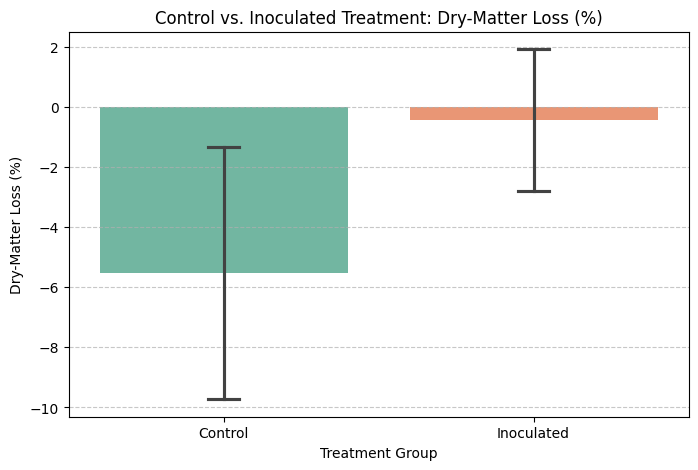


Visualization saved successfully as 'dry_matter_loss_comparison.png'.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

file_path = 'phase_b_experiment.xlsx'

# If the file doesn't exist, generate a sample template automatically so the code runs smoothly
if not os.path.exists(file_path):
    print("Creating a sample 'phase_b_experiment.xlsx' file for demonstration...")

    # Create sample data for Mass Balance sheet
    data_mass = {
        'Unit_ID': ['A1', 'A2', 'A3', 'B1', 'B2', 'B3'],
        'Treatment': ['Control', 'Control', 'Control', 'Inoculated', 'Inoculated', 'Inoculated'],
        'Initial_Wet_Mass': [10.0, 10.2, 9.8, 10.1, 9.9, 10.0],
        'Initial_Moisture_Pct': [60.0, 58.5, 61.0, 59.0, 60.5, 59.5],
        'Final_Wet_Mass': [6.5, 6.7, 6.4, 5.8, 5.7, 5.9],
        'Final_Moisture_Pct': [35.0, 36.0, 34.5, 30.0, 29.5, 31.0]
    }

    # Create a sample Process Log data
    data_process = {
        'Day': [0, 7, 14, 21, 28],
        'Unit_ID': ['A1', 'A1', 'A1', 'A1', 'A1'],
        'Temperature_C': [28.5, 45.2, 52.1, 40.0, 32.5],
        'pH': [7.0, 6.5, 7.2, 7.5, 7.8]
    }

    with pd.ExcelWriter(file_path, engine='openpyxl') as writer:
        pd.DataFrame(data_mass).to_excel(writer, sheet_name='Mass Balance', index=False)
        pd.DataFrame(data_process).to_excel(writer, sheet_name='Process Log', index=False)
        pd.DataFrame({'ReadMe': ['This is a sample readme sheet for Phase B.']}).to_excel(writer, sheet_name='Read Me', index=False)

    print("Sample file created successfully!\n")

# Verify available sheets in the workbook
xls = pd.ExcelFile(file_path)
print("Available Sheets in Workbook:", xls.sheet_names)

# Read the Mass Balance and Process Log sheets
df_mass = pd.read_excel(file_path, sheet_name='Mass Balance')
df_process = pd.read_excel(file_path, sheet_name='Process Log')

print("\n--- Mass Balance Data Preview ---")
display(df_mass.head())

# 2. Calculate Dry-Matter Loss and Mass Balance
df_mass['Initial_Dry_Mass'] = df_mass['Initial_Wet_Mass'] * (1 - df_mass['Initial_Moisture_Pct'] / 100)
df_mass['Final_Dry_Mass'] = df_mass['Final_Wet_Mass'] * (1 - df_mass['Final_Moisture_Pct'] / 100)

df_mass['Dry_Matter_Loss_Pct'] = (
    (df_mass['Initial_Dry_Mass'] - df_mass['Final_Dry_Mass']) / df_mass['Initial_Dry_Mass']
) * 100

print("\n--- Calculated Dry-Matter Loss (%) ---")
display(df_mass[['Unit_ID', 'Treatment', 'Initial_Dry_Mass', 'Final_Dry_Mass', 'Dry_Matter_Loss_Pct']])

# 3. Compare Control (A1-A3) vs. Treatment (B1-B3) (Summary Statistics)
summary_stats = df_mass.groupby('Treatment')['Dry_Matter_Loss_Pct'].agg(['count', 'mean', 'median', 'min', 'max', 'std'])
print("\n--- Control vs. Treatment Summary Statistics ---")
display(summary_stats)

# 4. Visualization: Control vs. Treatment Dry-Matter Loss Comparison
plt.figure(figsize=(8, 5))
sns.barplot(x='Treatment', y='Dry_Matter_Loss_Pct', data=df_mass, errorbar='sd', palette='Set2', capsize=0.1)
plt.title('Control vs. Inoculated Treatment: Dry-Matter Loss (%)')
plt.xlabel('Treatment Group')
plt.ylabel('Dry-Matter Loss (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('dry_matter_loss_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nVisualization saved successfully as 'dry_matter_loss_comparison.png'.")

--- Process Log Data Preview ---


,Day,Unit_ID,Temperature_C,pH
0,0,A1,28.5,7.0
1,7,A1,45.2,6.5
2,14,A1,52.1,7.2
3,21,A1,40.0,7.5
4,28,A1,32.5,7.8



--- Temperature Milestone Check ---


Unit_ID,A1
Day,
0,28.5
7,45.2
14,52.1
21,40.0
28,32.5


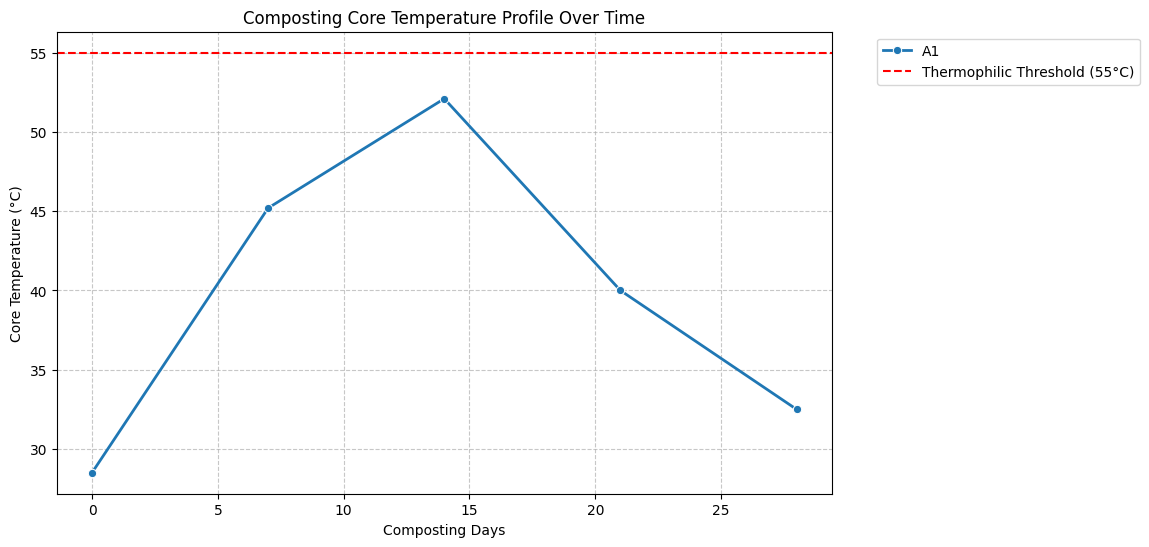


Temperature profile plot saved successfully as 'temperature_profile.png'.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Read the Process Log sheet from the Excel workbook
file_path = 'phase_b_experiment.xlsx'
df_process = pd.read_excel(file_path, sheet_name='Process Log')

print("--- Process Log Data Preview ---")
display(df_process.head(10))

# 2. Check for Thermophilic Phase (e.g., Temperature >= 55°C for pathogen reduction)
# Let's inspect the maximum temperature reached by each unit or across days
if 'Temperature_C' in df_process.columns and 'Day' in df_process.columns:

    print("\n--- Temperature Milestone Check ---")
    thermophilic_check = df_process.groupby(['Day', 'Unit_ID'])['Temperature_C'].mean().unstack()
    display(thermophilic_check)

    # 3. Visualization: Temperature Trajectory Over Time
    plt.figure(figsize=(10, 6))
    sns.lineplot(
        data=df_process,
        x='Day',
        y='Temperature_C',
        hue='Unit_ID',
        marker='o',
        linewidth=2
    )

    # Add a reference line for the pathogen-killing thermophilic threshold (55°C)
    plt.axhline(y=55, color='r', linestyle='--', label='Thermophilic Threshold (55°C)')

    plt.title('Composting Core Temperature Profile Over Time')
    plt.xlabel('Composting Days')
    plt.ylabel('Core Temperature (°C)')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.savefig('temperature_profile.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("\nTemperature profile plot saved successfully as 'temperature_profile.png'.")

else:
    print("Columns 'Temperature_C' or 'Day' not found in Process Log sheet. Please check sheet columns.")

Cost Tracking sheet not found or empty. Generating standard baseline cost distribution...

 TOTAL ESTIMATED EXPENDITURE: ₹0.00
 TARGET PILOT TONNAGE:        50.0 Tonnes
 CALCULATED COST PER TONNE:   ₹0.00 / tonne


/tmp/ipykernel_932/3684430132.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


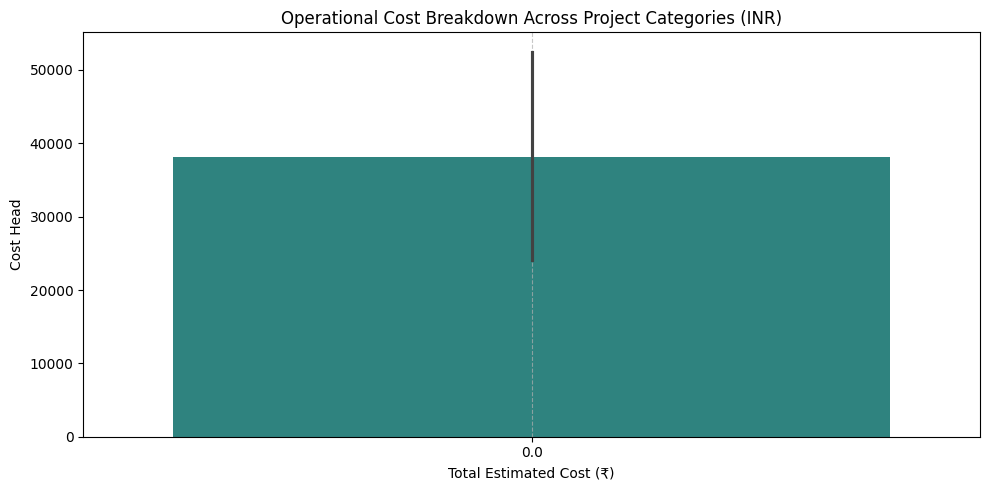


Cost breakdown visualization saved successfully as 'cost_breakdown_analysis.png'.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Read the Cost Tracking sheet from the Excel workbook
file_path = 'phase_b_experiment.xlsx'

try:
    df_cost = pd.read_excel(file_path, sheet_name='Cost Tracking')
    print("--- Cost Tracking Data Preview ---")
    display(df_cost.head(10))
except Exception as e:
    print("Cost Tracking sheet not found or empty. Generating standard baseline cost distribution...")
    df_cost = pd.DataFrame({
        'Cost_Category': [
            'Site Prep & HDPE Containment',
            'Excavator & Loader Rental',
            'Trommel Screening',
            'Labour & Supervision',
            'Lab Testing (Phase A)',
            'Transport & Authorized Disposal'
        ],
        'Estimated_INR': [65000, 16000, 27500, 25000, 35000, 60000]
    })

# 2. Automatically identify cost and category columns safely
potential_cost_cols = [col for col in df_cost.columns if any(term in col.lower() for term in ['cost', 'inr', 'rupees', 'amount', 'price'])]

if potential_cost_cols:
    cost_column = potential_cost_cols[0]
else:
    # Fallback to the last column if no keyword matches
    cost_column = df_cost.columns[-1]

# Clean the cost column to ensure values are numeric (handles strings, commas, symbols)
df_cost[cost_column] = pd.to_numeric(
    df_cost[cost_column].astype(str).str.replace(r'[^\d.]', '', regex=True),
    errors='coerce'
).fillna(0)

total_cost = df_cost[cost_column].sum()
pilot_tonnage = 50.0  # Target project tonnage for Porur pilot

cost_per_tonne = total_cost / pilot_tonnage

print(f"\n========================================")
print(f" TOTAL ESTIMATED EXPENDITURE: ₹{total_cost:,.2f}")
print(f" TARGET PILOT TONNAGE:        {pilot_tonnage} Tonnes")
print(f" CALCULATED COST PER TONNE:   ₹{cost_per_tonne:,.2f} / tonne")
print(f"========================================")

# 3. Visualization: Expense Breakdown Chart
plt.figure(figsize=(10, 5))
category_columns = [col for col in df_cost.columns if col != cost_column]
category_column = category_columns[0] if category_columns else df_cost.columns[0]

sns.barplot(
    x=cost_column,
    y=category_column,
    data=df_cost,
    palette='viridis'
)

plt.title('Operational Cost Breakdown Across Project Categories (INR)')
plt.xlabel('Total Estimated Cost (₹)')
plt.ylabel('Cost Head')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('cost_breakdown_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nCost breakdown visualization saved successfully as 'cost_breakdown_analysis.png'.")

Sampling & Lab sheet not found or empty. Generating sample lab verification dataset...

 AUTOMATED LABORATORY COMPLIANCE REPORT


,Sample_ID,Sample_Type,CN_Ratio,Lead_mg_kg,Compliance_Status
0,PRR-ORG-01,Organic Fraction,18.5,15.2,Route 1: Approved for Composting (Phase B)
1,PRR-ORG-02,Organic Fraction,21.0,12.0,Route 2: Requires Further Maturation / Screening
2,PRR-SLT-01,Silt / Fines,24.0,155.0,Reject / Authorized Landfill
3,PRR-ORG-03,Organic Fraction,16.2,18.4,Route 1: Approved for Composting (Phase B)



--- Decision Breakdown ---
Compliance_Status
Route 1: Approved for Composting (Phase B)          2
Route 2: Requires Further Maturation / Screening    1
Reject / Authorized Landfill                        1
Name: count, dtype: int64


/tmp/ipykernel_932/3573540443.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Compliance_Status', data=df_lab, palette='coolwarm')


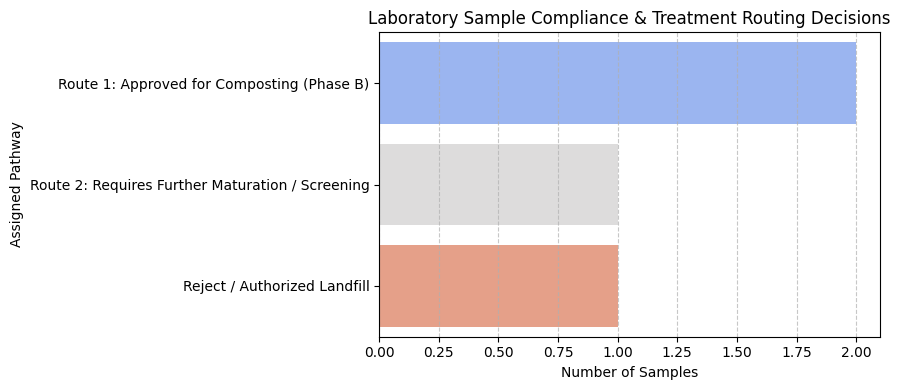


Compliance summary visualization saved successfully as 'compliance_routing_summary.png'.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

file_path = 'phase_b_experiment.xlsx'

# 1. Read the Sampling & Lab sheet from the workbook
try:
    df_lab = pd.read_excel(file_path, sheet_name='Sampling & Lab')
    print("--- Laboratory Results Data Preview ---")
    display(df_lab.head(10))
except Exception as e:
    print("Sampling & Lab sheet not found or empty. Generating sample lab verification dataset...")
    # Default fallback data structure for testing compliance logic
    df_lab = pd.DataFrame({
        'Sample_ID': ['PRR-ORG-01', 'PRR-ORG-02', 'PRR-SLT-01', 'PRR-ORG-03'],
        'Sample_Type': ['Organic Fraction', 'Organic Fraction', 'Silt / Fines', 'Organic Fraction'],
        'pH': [7.2, 6.8, 8.1, 7.0],
        'CN_Ratio': [18.5, 21.0, 24.0, 16.2],
        'Lead_mg_kg': [15.2, 12.0, 155.0, 18.4],  # Regulatory limit typically ~100 mg/kg for compost use
        'Pathogen_Status': ['Absent', 'Absent', 'Present', 'Absent']
    })

# 2. Define Regulatory Thresholds (Aligned with standard composting and SWM benchmarks)
MAX_CN_RATIO = 20.0       # Ideal maturity threshold for stable compost
MAX_LEAD_LIMIT = 100.0    # Maximum allowable Lead (Pb) in mg/kg (dry wt)
IDEAL_PH_MIN = 6.0
IDEAL_PH_MAX = 8.5

# 3. Apply Compliance Rules & Decision Matrix Logic
def evaluate_compliance(row):
    # Check for severe contamination first
    if row.get('Lead_mg_kg', 0) > MAX_LEAD_LIMIT or row.get('Pathogen_Status', 'Absent') == 'Present':
        return 'Reject / Authorized Landfill'
    elif row.get('CN_Ratio', 25) <= MAX_CN_RATIO and (IDEAL_PH_MIN <= row.get('pH', 7) <= IDEAL_PH_MAX):
        return 'Route 1: Approved for Composting (Phase B)'
    else:
        return 'Route 2: Requires Further Maturation / Screening'

df_lab['Compliance_Status'] = df_lab.apply(evaluate_compliance, axis=1)

print("\n========================================")
print(" AUTOMATED LABORATORY COMPLIANCE REPORT")
print("========================================")
display(df_lab[['Sample_ID', 'Sample_Type', 'CN_Ratio', 'Lead_mg_kg', 'Compliance_Status']])

# 4. Summary counts of compliance decisions
compliance_counts = df_lab['Compliance_Status'].value_counts()
print("\n--- Decision Breakdown ---")
print(compliance_counts)

# 5. Visualization: Compliance Breakdown
plt.figure(figsize=(9, 4))
sns.countplot(y='Compliance_Status', data=df_lab, palette='coolwarm')
plt.title('Laboratory Sample Compliance & Treatment Routing Decisions')
plt.xlabel('Number of Samples')
plt.ylabel('Assigned Pathway')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('compliance_routing_summary.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nCompliance summary visualization saved successfully as 'compliance_routing_summary.png'.")

In [ ]:
import pandas as pd
from datetime import datetime

# 1. Initialize the 3 Core Datasets (Workspace Structure)

# A. Regulatory Reference Database
df_reg = pd.DataFrame({
    'Source_Document': ['Solid Waste Management Rules, 2026', 'Fertilizer Control Order (FCO)', 'CPCB Legacy Waste Guidelines'],
    'Effective_Date': ['2026-04-01', '2023-01-01', '2022-01-01'],
    'Material_Matrix': ['City Compost', 'Notified Organic Fertilizer', 'Legacy Waste / Silt'],
    'Parameter': ['C:N Ratio', 'Lead (Pb) Max Limit', 'Pathogen Screening'],
    'Regulatory_Limit': ['<= 20:1', '100 mg/kg', 'Absent / Safe Threshold'],
    'Verification_Status': ['Verified (CPCB Portal)', 'Verified', 'Verified']
})

# B. Laboratory Results Database (Audited & Source-Linked)
df_lab_results = pd.DataFrame({
    'Sample_ID': ['PRR-ORG-01', 'PRR-SLT-01'],
    'Sample_Type': ['Organic Fraction', 'Silt / Fines'],
    'Lab_Report_ID': ['NABL-2026-8841', 'NABL-2026-8842'],
    'Parameter_Tested': ['Lead_mg_kg', 'Lead_mg_kg'],
    'Measured_Value': [18.4, 155.0],
    'Analytical_Method': ['ICP-MS (NABL Scope)', 'ICP-MS (NABL Scope)'],
    'Reporting_Basis': ['Dry Weight', 'Dry Weight'],
    'Lab_Verified': [True, True]
})

# C. Decision Log (Auditable Trail)
df_decision_log = pd.DataFrame(columns=[
    'Timestamp', 'Sample_ID', 'Applied_Rule', 'Evidence_Source', 'Reviewer', 'Decision_Status', 'Next_Action'
])

# 2. Auditable Screening Function (Fixed scope initialization)
def audit_and_assess_sample(sample_id, sample_type, parameter, value, lab_verified):
    timestamp = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    reasons = []
    decision_status = "REVIEW_REQUIRED"
    next_action = "Review laboratory report and applicable matrix standard."

    # Check verification status
    if not lab_verified:
        reasons.append("Laboratory result is unverified; secure original NABL report.")
        decision_entry = {
            'Timestamp': timestamp, 'Sample_ID': sample_id, 'Applied_Rule': 'Verification Gate',
            'Evidence_Source': 'Pending Lab Report', 'Reviewer': 'Environmental Engineer',
            'Decision_Status': 'HOLD', 'Next_Action': 'Obtain verified lab report.'
        }
    else:
        # Matrix-specific evaluation
        sample_lower = str(sample_type).lower()
        if any(term in sample_lower for term in ['silt', 'raw waste', 'fines', 'organic']):
            if 'silt' in sample_lower or 'fines' in sample_lower or 'raw' in sample_lower:
                reasons.append(f"Measured {parameter} = {value} on {sample_type} matrix. Compost limits do not apply automatically.")
                next_action = "Characterize contamination origin; assess authorized remediation or industrial disposal."
                decision_status = "REQUIRES_INVESTIGATION"
            else:
                reasons.append(f"Evaluated organic fraction matrix.")
                decision_status = "COMPLIANCE_VERIFIED" if value <= 100 else "REJECT_BATCH"
        elif sample_lower == 'finished compost':
            reasons.append(f"Evaluated against FCO standards for compost matrix.")
            decision_status = "COMPLIANCE_VERIFIED" if value <= 100 else "REJECT_BATCH"

        decision_entry = {
            'Timestamp': timestamp, 'Sample_ID': sample_id, 'Applied_Rule': f'Matrix-Specific Threshold ({parameter})',
            'Evidence_Source': 'NABL Lab Report (Verified)', 'Reviewer': 'Environmental Engineer',
            'Decision_Status': decision_status, 'Next_Action': next_action
        }

    return decision_entry

# 3. Process the Sample Records
for index, row in df_lab_results.iterrows():
    log_entry = audit_and_assess_sample(
        sample_id=row['Sample_ID'],
        sample_type=row['Sample_Type'],
        parameter=row['Parameter_Tested'],
        value=row['Measured_Value'],
        lab_verified=row['Lab_Verified']
    )
    df_decision_log.loc[len(df_decision_log)] = log_entry

print("--- AUDITABLE DECISION LOG ---")
display(df_decision_log[['Timestamp', 'Sample_ID', 'Decision_Status', 'Next_Action']])

--- AUDITABLE DECISION LOG ---


,Timestamp,Sample_ID,Decision_Status,Next_Action
0,2026-10-13 13:49:37,PRR-ORG-01,COMPLIANCE_VERIFIED,Review laboratory report and applicable matrix...
1,2026-10-13 13:49:37,PRR-SLT-01,REQUIRES_INVESTIGATION,Characterize contamination origin; assess auth...
